In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

In [2]:

data = load_breast_cancer(as_frame=True)
df = data.frame

print("Shape:", df.shape)
display(df.head())


Shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
X = df[["mean radius","mean area"]]
print(X.head())

   mean radius  mean area
0        17.99     1001.0
1        20.57     1326.0
2        19.69     1203.0
3        11.42      386.1
4        20.29     1297.0


In [4]:
sc = StandardScaler()
Xs = sc.fit_transform(X)

In [5]:
model = DBSCAN(eps=0.4, min_samples=5)
labels = model.fit_predict(Xs)

print("Cluster Labels: ", np.unique(labels))


Cluster Labels:  [-1  0  1]


In [6]:
nc = len(set(labels)) - (1 if -1 in labels else 0)
nn = list(labels).count(-1)

print("number of clusters: ", nc)
print("number of noise Points: ", nn)

number of clusters:  2
number of noise Points:  5


In [7]:
score = silhouette_score(
    Xs[labels != -1],
    labels[labels != -1]
)

print("Silhouette Score: ", score)

Silhouette Score:  0.5993424874893749


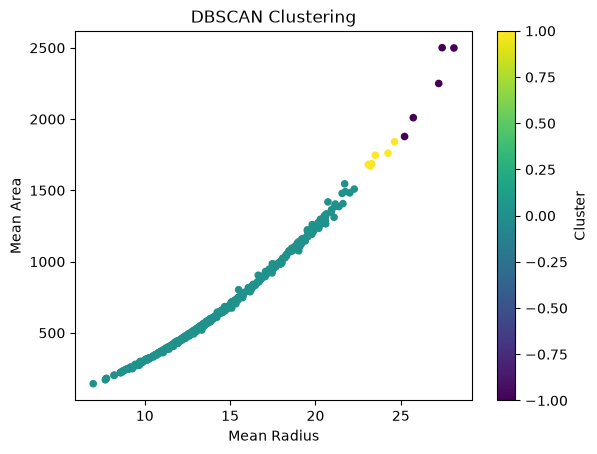

In [8]:
plt.scatter(
    X["mean radius"],
    X["mean area"],
    c=labels,
    cmap="viridis",
    s=20
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Area")
plt.title("DBSCAN Clustering")
plt.colorbar(label="Cluster")
plt.show()